# 📘 Notebook 01: The Perceptron and the Multilayer Perceptron

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Papers: Rosenblatt (1958) · Minsky and Papert (1969) · Rumelhart, Hinton and Williams (1986)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab to train everything yourself.
>
> ⏱️ **Training time and limitations.** Every model here trains in a few seconds on an ordinary laptop processor; no GPU is needed. The perceptron is written from scratch exactly as in the 1958 paper; the multilayer networks use PyTorch. The datasets are small two-dimensional toy problems, chosen so that every decision a model makes can be drawn on a page. They show the **ideas** of the papers, not their original experiments: Rosenblatt's perceptron was a machine with photocells and motors, and the 1986 paper tested several tasks that we do not reproduce.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain the **perceptron**: a weighted sum, a threshold and a learning rule
- Implement and train a perceptron **from scratch** in NumPy
- Show **why** a single perceptron cannot learn XOR, the result that stalled the field
- Explain how a **hidden layer** and **backpropagation** remove that limit
- See what a hidden layer **does** to the data: it bends the space until the classes become separable
- Compare a perceptron and an MLP on a harder dataset, and measure the effect of the **width** of the hidden layer

> **Prerequisites:** basic Python and NumPy. Gradients and backpropagation are explained in detail in [From Python to Deep Learning and Fine-Tuning](https://giannis00.github.io/teaching/#deep-learning); here we focus on what the papers proposed and why it mattered.
>
> 🔭 **Why this notebook matters:** every architecture in this course, from LeNet to the Transformer, is built from the same unit: a weighted sum followed by a non-linear function. The story of the perceptron, its famous failure and its rescue by hidden layers, explains why networks are **deep** at all.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__)

PyTorch 2.2.2+cpu


## 1. The paper: a machine that learns (Rosenblatt, 1958)

> 📄 F. Rosenblatt, [*The perceptron: a probabilistic model for information storage and organization in the brain*](https://doi.org/10.1037/h0042519), Psychological Review 65(6), 1958.

### Intuition first
Rosenblatt wanted a machine that could learn to recognise patterns from examples, loosely inspired by neurons. His **perceptron** looks at a set of inputs, multiplies each by a **weight**, adds them up with a **bias**, and fires (outputs 1) if the total is above zero, otherwise outputs 0.

Learning is just as simple. Show the machine an example. If it answers correctly, do nothing. If it answers 0 when it should have said 1, **add** the input to the weights, so the sum grows next time; if it answers 1 when it should have said 0, **subtract** it.

### Formal definition
For an input $x$, the output is $\hat{y} = 1$ if $w \cdot x + b > 0$, else $0$. After each example, with learning rate $\eta$:

$$w \leftarrow w + \eta\,(y - \hat{y})\,x, \qquad b \leftarrow b + \eta\,(y - \hat{y})$$

When the answer is right, $y - \hat{y} = 0$ and nothing changes.

In [2]:
class Perceptron:
    """Rosenblatt's perceptron, written from scratch."""

    def __init__(self, n_inputs, lr=0.1):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr = lr

    def predict(self, X):
        return (X @ self.w + self.b > 0).astype(int)

    def fit(self, X, y, epochs=50):
        mistakes = []
        for _ in range(epochs):
            errors = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - self.predict(xi[None])[0])
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            mistakes.append(errors)
        return mistakes

## 2. Learning AND and OR

The four possible inputs of two switches, and the answers of the logical functions **AND** (both on) and **OR** (at least one on).

In [3]:
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
targets = {"AND": np.array([0, 0, 0, 1]), "OR": np.array([0, 1, 1, 1]), "XOR": np.array([0, 1, 1, 0])}

for name in ["AND", "OR"]:
    p = Perceptron(2)
    mistakes = p.fit(X_logic, targets[name], epochs=20)
    first_clean = mistakes.index(0) + 1 if 0 in mistakes else None
    print(f"{name}: predictions {p.predict(X_logic)}, weights {p.w}, bias {p.b:.1f}, "
          f"no mistakes from epoch {first_clean}")

AND: predictions [0 0 0 1], weights [0.2 0.1], bias -0.2, no mistakes from epoch 6
OR: predictions [0 1 1 1], weights [0.1 0.1], bias 0.0, no mistakes from epoch 4


**What we see.** Both functions are learned perfectly. For AND the perceptron settles on weights **0.2 and 0.1** with bias **-0.2**: the sum is above zero only when both inputs are on. For OR, weights **0.1 and 0.1** with bias **0**: either input is enough. AND needs **6** passes over the four examples before the last mistake disappears, OR only **4**. This is the **perceptron convergence theorem** at work: if a line that separates the classes exists, the rule is guaranteed to find one.

## 3. The famous failure: XOR

**XOR** ("exclusive or") is 1 when exactly **one** switch is on. It looks no harder than OR.

In [4]:
p_xor = Perceptron(2)
mistakes_xor = p_xor.fit(X_logic, targets["XOR"], epochs=100)
print("Mistakes in the last 10 epochs:", mistakes_xor[-10:])
print("Predictions after 100 epochs:", p_xor.predict(X_logic), " target:", targets["XOR"])

Mistakes in the last 10 epochs: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Predictions after 100 epochs: [1 1 0 0]  target: [0 1 1 0]


**What we see.** After 100 passes the perceptron still makes **4 mistakes in every epoch**, all four examples, and its final answers `[1 1 0 0]` have nothing to do with the target `[0 1 1 0]`. It is not learning slowly: it is cycling forever, because every update that fixes one point breaks another.

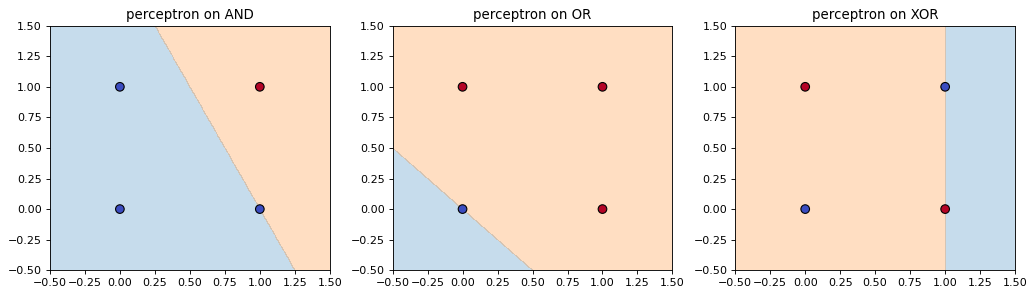

In [5]:
def draw(model_predict, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    zone = model_predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, alpha=0.25, levels=[-0.5, 0.5, 1.5], colors=["tab:blue", "tab:orange"])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=60 if len(X) < 10 else 12)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name in zip(axes, ["AND", "OR", "XOR"]):
    p = Perceptron(2)
    p.fit(X_logic, targets[name], epochs=100)
    draw(p.predict, X_logic, targets[name], ax, f"perceptron on {name}")
plt.tight_layout()
plt.show()

**What we see.** A perceptron can only draw **one straight line** and say "1 on this side, 0 on the other". For AND and OR such a line exists. For XOR the two 1s sit on **opposite corners**, and no straight line can separate them from the two 0s: whatever line the perceptron tries, at least one point is on the wrong side, which is why the mistakes never stop.

> 📄 M. Minsky and S. Papert, [*Perceptrons: An Introduction to Computational Geometry*](https://mitpress.mit.edu/9780262630221/perceptrons/), MIT Press, 1969.

Minsky and Papert proved this limit rigorously in 1969. Their book is often blamed for the first "AI winter", a decade in which funding and interest in neural networks collapsed. They knew that **several layers** of perceptrons could compute XOR; what nobody had was a way to **train** them.

## 4. The rescue: hidden layers and backpropagation (1986)

> 📄 D. Rumelhart, G. Hinton and R. Williams, [*Learning representations by back-propagating errors*](https://doi.org/10.1038/323533a0), Nature 323, 1986.

### Intuition first
Put a **hidden layer** of units between the input and the output. Each hidden unit draws its own line; the output unit combines them. Two lines are enough for XOR: one cuts off the corner (0,0), the other the corner (1,1), and the output says "1 if between the lines".

The breakthrough of 1986 was making this **trainable**. The hard threshold of the perceptron has no slope, so it gives no hint which way to change a weight. Replace it with a smooth S-shaped function (the sigmoid), and the error at the output can be passed **backwards** through the network with the chain rule, telling every weight how much it contributed to the mistake. This is **backpropagation**.

In [6]:
class MLP(nn.Module):
    def __init__(self, hidden, n_inputs=2):
        super().__init__()
        self.hidden = nn.Linear(n_inputs, hidden)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x, return_hidden=False):
        h = torch.tanh(self.hidden(x))
        return (self.out(h), h) if return_hidden else self.out(h)

def train(model, X, y, epochs, lr=0.05):
    X, y = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).view(-1, 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward()
        opt.step()
    return loss.item()

def mlp_predict(model):
    return lambda X: (model(torch.tensor(X, dtype=torch.float32)) > 0).int().numpy().ravel()

torch.manual_seed(0)
mlp_xor = MLP(hidden=2)
final_loss = train(mlp_xor, X_logic, targets["XOR"], epochs=2000)
print("Final loss:", round(final_loss, 4), "  predictions:", mlp_predict(mlp_xor)(X_logic), " target:", targets["XOR"])

Final loss: 0.0002   predictions: [0 1 1 0]  target: [0 1 1 0]


**What we see.** With just **two hidden units**, the network learns XOR perfectly: predictions `[0 1 1 0]` and a final loss of **0.0002**. Training took two thousand tiny steps and well under a second.

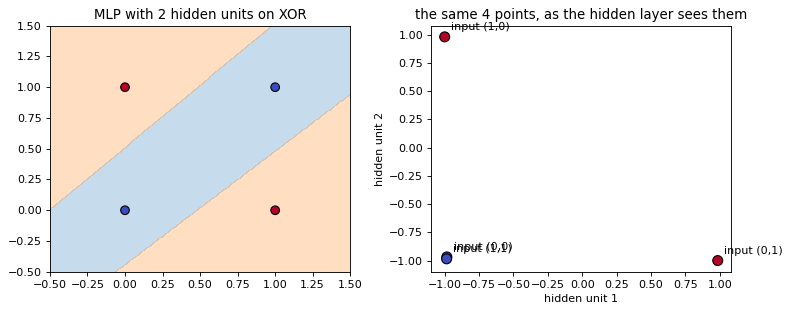

In [7]:
with torch.no_grad():
    _, hidden = mlp_xor(torch.tensor(X_logic, dtype=torch.float32), return_hidden=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw(mlp_predict(mlp_xor), X_logic, targets["XOR"], axes[0], "MLP with 2 hidden units on XOR")
axes[1].scatter(hidden[:, 0], hidden[:, 1], c=targets["XOR"], cmap="coolwarm", edgecolors="k", s=80)
for (a, b), xy in zip(X_logic.astype(int), hidden.numpy()):
    axes[1].annotate(f"input ({a},{b})", xy, textcoords="offset points", xytext=(6, 6))
axes[1].set_title("the same 4 points, as the hidden layer sees them")
axes[1].set_xlabel("hidden unit 1")
axes[1].set_ylabel("hidden unit 2")
plt.tight_layout()
plt.show()

**What we see.** Left: the MLP draws **two parallel lines**, a band that holds (0,0) and (1,1) and leaves the other two corners outside, exactly the two-line solution described above. Right: the hidden layer has **moved the points**. (0,0) and (1,1), the two 0s, are mapped to the same place, around (-1, -1), while the two 1s go to two other corners. In this new space a single straight line separates the classes, and the output unit is just a perceptron again.

This is the deepest idea in the notebook, and the title of the 1986 paper says it: the network **learns representations**. A hidden layer transforms the data into a new space where a simple decision becomes possible. Every architecture in this course is a more elaborate answer to the same question: *what representation makes the problem easy?*

## 5. A harder problem: two moons

XOR has four points. A more realistic test: 1,000 noisy points in two interleaved half-moons. We keep 30% aside to measure accuracy on points the models have not seen.

Test accuracy: perceptron 0.853, MLP with 16 hidden units 0.973


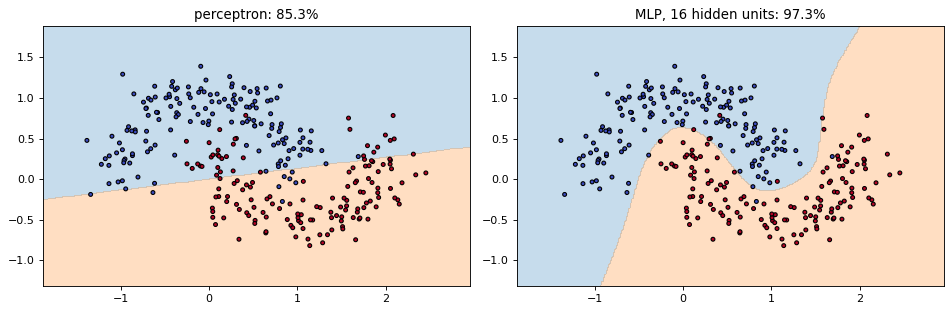

In [8]:
X_moons, y_moons = make_moons(n_samples=1000, noise=0.2, random_state=0)
idx = np.random.default_rng(0).permutation(len(X_moons))
train_idx, test_idx = idx[:700], idx[700:]
Xtr, ytr, Xte, yte = X_moons[train_idx], y_moons[train_idx], X_moons[test_idx], y_moons[test_idx]

perc = Perceptron(2)
perc.fit(Xtr, ytr, epochs=50)
torch.manual_seed(0)
mlp_moons = MLP(hidden=16)
train(mlp_moons, Xtr, ytr, epochs=1000)

acc_perc = (perc.predict(Xte) == yte).mean()
acc_mlp = (mlp_predict(mlp_moons)(Xte) == yte).mean()
print(f"Test accuracy: perceptron {acc_perc:.3f}, MLP with 16 hidden units {acc_mlp:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw(perc.predict, Xte, yte, axes[0], f"perceptron: {acc_perc:.1%}")
draw(mlp_predict(mlp_moons), Xte, yte, axes[1], f"MLP, 16 hidden units: {acc_mlp:.1%}")
plt.tight_layout()
plt.show()

**What we see.** On points it has never seen, the perceptron is right **85.3%** of the time: its single straight line cuts through both moons. The MLP with 16 hidden units bends its boundary around the moons and reaches **97.3%**. The remaining mistakes are points that the noise pushed deep into the other moon, which no sensible boundary should chase.

## 6. How wide should the hidden layer be?

In [9]:
widths = [1, 2, 3, 4, 8, 16, 64]
results = {}
for h in widths:
    torch.manual_seed(0)
    m = MLP(hidden=h)
    train(m, Xtr, ytr, epochs=1000)
    results[h] = ((mlp_predict(m)(Xtr) == ytr).mean(), (mlp_predict(m)(Xte) == yte).mean())
for h, (tr, te) in results.items():
    print(f"{h:3d} hidden units: train {tr:.3f}  test {te:.3f}")

  1 hidden units: train 0.869  test 0.843
  2 hidden units: train 0.886  test 0.860
  3 hidden units: train 0.966  test 0.967
  4 hidden units: train 0.967  test 0.967
  8 hidden units: train 0.967  test 0.970
 16 hidden units: train 0.967  test 0.973
 64 hidden units: train 0.969  test 0.973


**What we see.** One and two hidden units are not enough (about **84 to 86%** on test): the boundary cannot bend enough. From **three** units the accuracy jumps to about **97%**, and adding more, up to 64, changes almost nothing (**97.0 to 97.3%**). Training and test accuracy stay close at every width, so on this problem the extra units do not overfit; they simply have nothing left to learn. More capacity helps only up to what the problem needs.

## ⚠️ Common pitfalls

- **Thinking the perceptron "learns slowly" on XOR.** It does not learn it at all; no amount of training can draw one line through XOR.
- **Using a step function in a multilayer network.** It has no slope, so backpropagation has nothing to pass back. Hidden units need a smooth non-linearity (sigmoid, tanh, ReLU).
- **Stacking layers without a non-linearity.** Two linear layers in a row are still one linear function: the hidden layer would add nothing.
- **Judging by training accuracy.** A wide network can fit noise; always measure on held-out data.
- **Forgetting the seed.** Small networks are sensitive to their random starting weights; fix the seed to compare fairly, and try several to be sure.

## ✏️ Exercises

### Exercise 1 (A perceptron that does not converge on separable data?)
The perceptron convergence theorem says that if the data **is** separable by a line, the learning rule finds one in a finite number of steps. Train a perceptron on OR with learning rate 0.01 and with 1.0. Does the number of epochs needed change? Do the final predictions?

In [10]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for lr in [0.01, 1.0]:
    p = Perceptron(2, lr=lr)
    m = p.fit(X_logic, targets["OR"], epochs=20)
    print(f"lr {lr}: no mistakes from epoch {m.index(0) + 1}, predictions {p.predict(X_logic)}")
```

*Because the weights start at zero and every update has the same size, changing the learning rate only rescales the weights; the line and the number of epochs stay the same. This is a special property of the perceptron with zero initial weights, not of neural networks in general.*
</details>

### Exercise 2 (XOR with one hidden unit)
Train the MLP of Section 4 on XOR with **one** hidden unit, for several seeds. Can it ever solve XOR? Why?

In [11]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for seed in range(5):
    torch.manual_seed(seed)
    m = MLP(hidden=1)
    train(m, X_logic, targets["XOR"], epochs=2000)
    print(seed, mlp_predict(m)(X_logic))
```

*With one hidden unit, the hidden layer maps the four points onto a single line of numbers, and the output can only split that line once. XOR needs the two 1s to be separated from the 0s on both sides, so one unit is never enough; two is the minimum.*
</details>

### Exercise 3 (Which non-linearity?)
Replace `torch.tanh` in the MLP by `torch.relu` and by the identity (no non-linearity at all). Train each with 16 hidden units on the moons and compare test accuracy.

In [12]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
class MLP2(MLP):
    def __init__(self, hidden, act):
        super().__init__(hidden)
        self.act = act
    def forward(self, x, return_hidden=False):
        return self.out(self.act(self.hidden(x)))

for name, act in [("tanh", torch.tanh), ("relu", torch.relu), ("none", lambda z: z)]:
    torch.manual_seed(0)
    m = MLP2(16, act)
    train(m, Xtr, ytr, epochs=1000)
    print(name, round((mlp_predict(m)(Xte) == yte).mean(), 3))
```

*With no non-linearity, the network collapses to a straight line and scores like the perceptron. Tanh and ReLU both bend the boundary; ReLU, introduced to deep networks around 2010 and used in AlexNet (Notebook 03), has become the default because it trains faster in deep networks.*
</details>

## 🔑 Key takeaways

- The **perceptron** (1958) is a weighted sum and a threshold, trained by adding or subtracting misclassified inputs.
- It can only draw **one straight line**, so it cannot learn XOR; Minsky and Papert proved this in 1969.
- A **hidden layer** with a smooth non-linearity, trained by **backpropagation** (1986), removes the limit.
- Hidden layers **learn representations**: they transform the data until a simple decision works.
- Width adds flexibility, but beyond what the problem needs it does not help on unseen data.

---
**Next:** *Notebook 02: LeNet-5*, where the hidden layers become **convolutions** that look at small patches of an image, and the network reads handwritten digits.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*